# Part 3 — Ensembles, regularization and hyperparameter optimisation

**Project:** Predict Students' Dropout and Academic Success (UCI dataset 697, CC BY 4.0). **Task:** three-class classification (`Dropout`, `Enrolled`, `Graduate`) from information available by the end of semester 2. **Primary metric:** macro F1, with accuracy, balanced accuracy, one-vs-rest ROC-AUC and per-class recall alongside it.

**Part 2 baseline to beat:** a tuned decision tree (nested-CV macro F1 0.676) and Bernoulli Naive Bayes (0.671); the two were statistically tied, and `Enrolled` was the weak class.

This notebook

1. trains and compares **Random Forest**, **AdaBoost** and **XGBoost**;
2. applies **Ridge (L2), Lasso (L1) and Elastic-Net** regularization through multinomial logistic regression, the linear model that fits a three-class task;
3. tunes every model with a systematic search (**randomized search** for the ensembles, **grid search** for the regularized model) and estimates tuned performance with **nested cross-validation**, so tuning does not inflate the scores;
4. refits the tuned models on the full training partition and scores the **held-out test set once**, with bootstrap confidence intervals.

Part 1's split and preprocessing are restated unchanged in Section 0. Preprocessing lives **inside** every model pipeline, so each fold learns its own imputation, clip fences, scaling and encodings.

## 0. Setup — Part 1 split and preprocessing (unchanged)

In [1]:
import os
os.environ['PYTHONWARNINGS'] = 'ignore'   # inherited by joblib worker processes

import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats
from scipy.stats import loguniform, randint, uniform
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,
                             classification_report, f1_score, make_scorer, recall_score,
                             roc_auc_score)
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV, RepeatedStratifiedKFold,
                                     StratifiedKFold, cross_validate, train_test_split)
from sklearn.naive_bayes import BernoulliNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import KBinsDiscretizer, OneHotEncoder, RobustScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
SEED = 42
CLASSES = ['Dropout', 'Enrolled', 'Graduate']
CLASS_ID = {c: i for i, c in enumerate(CLASSES)}   # XGBoost needs integer labels

def locate_data():
    for path in (Path('../data.csv'), Path('data.csv')):
        if path.exists():
            return path
    raise FileNotFoundError('Run from assignment 3/ or the repository root; data.csv is required')

data = pd.read_csv(locate_data())
assert data.shape == (4424, 37)
X = data.drop(columns='Target')
y = data['Target'].map(CLASS_ID)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)  # identical to Parts 1 and 2
print('Training/test rows:', len(X_train), len(X_test), '| class ids:', CLASS_ID)
print('Class shares (train):', (y_train.value_counts(normalize=True).sort_index().round(3)).to_dict())

Training/test rows: 3539 885 | class ids: {'Dropout': 0, 'Enrolled': 1, 'Graduate': 2}
Class shares (train): {0: 0.321, 1: 0.179, 2: 0.499}


In [2]:
class AcademicFeatures(BaseEstimator, TransformerMixin):
    """Per-semester approval rates; a zero denominator becomes NaN and is imputed downstream."""
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        out = X.copy()
        for semester in ('1st', '2nd'):
            prefix = f'Curricular units {semester} sem'
            denominator = out[f'{prefix} (enrolled)'].replace(0, np.nan)
            out[f'{semester} approval rate'] = out[f'{prefix} (approved)'] / denominator
        return out


class IQRClipper(BaseEstimator, TransformerMixin):
    """Clip to training-fitted Tukey fences."""
    def fit(self, X, y=None):
        values = np.asarray(X, dtype=float)
        q1, q3 = np.percentile(values, [25, 75], axis=0)
        spread = q3 - q1
        self.lower_ = np.where(spread > 0, q1 - 1.5 * spread, -np.inf)
        self.upper_ = np.where(spread > 0, q3 + 1.5 * spread, np.inf)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lower_, self.upper_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


categorical = [
    'Marital status', 'Application mode', 'Course', 'Daytime/evening attendance',
    'Previous qualification', 'Nacionality', "Mother's qualification",
    "Father's qualification", "Mother's occupation", "Father's occupation",
]
binary = [
    'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date',
    'Gender', 'Scholarship holder', 'International',
]
constructed = ['1st approval rate', '2nd approval rate']
numeric = [c for c in X_train.columns if c not in categorical + binary] + constructed


def continuous_preprocessing():
    """Part 1 preprocessing: median impute, IQR clip, robust scale; one-hot categories."""
    return Pipeline([
        ('features', AcademicFeatures()),
        ('preprocess', ColumnTransformer([
            ('numeric', Pipeline([
                ('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
                ('clip', IQRClipper()),
                ('scale', RobustScaler())]), numeric),
            ('categorical', Pipeline([
                ('impute', SimpleImputer(strategy='most_frequent')),
                ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), categorical),
            ('binary', SimpleImputer(strategy='most_frequent'), binary),
        ], remainder='drop')),
    ])


def binned_preprocessing(n_bins=5):
    """All-binary representation for Bernoulli Naive Bayes (Part 2)."""
    return Pipeline([
        ('features', AcademicFeatures()),
        ('preprocess', ColumnTransformer([
            ('numeric', Pipeline([
                ('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
                ('bins', KBinsDiscretizer(n_bins=n_bins, encode='onehot-dense', strategy='quantile'))]), numeric),
            ('categorical', Pipeline([
                ('impute', SimpleImputer(strategy='most_frequent')),
                ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), categorical),
            ('binary', SimpleImputer(strategy='most_frequent'), binary),
        ], remainder='drop')),
    ])


def with_model(preprocessing, model):
    return Pipeline([('prep', preprocessing), ('model', model)])

print('Prepared feature count:', continuous_preprocessing().fit_transform(X_train).shape[1])

Prepared feature count: 239


## 1. Models and search spaces

Class imbalance (`Enrolled` is 18 % of students) is handled **inside each estimator's fit**, never by resampling the data: `class_weight` for Random Forest, balanced per-sample weights computed from each training fold's labels for AdaBoost and XGBoost (scikit-learn's AdaBoost and XGBoost's multiclass objective have no `class_weight` argument). This keeps the weights fold-local and leak-free.

| Model | Tuned hyperparameters | Search |
|---|---|---|
| **Random Forest** | trees, depth, min leaf size, features per split, class weighting | randomized, 15 draws per inner search (40 for the final fit) |
| **AdaBoost** (tree base learner) | trees, learning rate, base-tree depth | randomized |
| **XGBoost** | trees, learning rate, depth, min child weight, row/column subsampling, L2 (`reg_lambda`) and L1 (`reg_alpha`) leaf penalties | randomized |
| **Regularized logistic regression** | inverse strength `C` (7 values, 10⁻³ … 1) × `l1_ratio` ∈ {0 (Ridge), 0.5 (Elastic-Net), 1 (Lasso)} | exhaustive grid |
| Part 2 baselines | same grids as Part 2 for the tree; none for Bernoulli NB | grid / none |

Randomized search samples the space broadly for the same budget as a coarse grid would spend on a few values of each parameter (Bergstra & Bengio, 2012), which is why it is used for the high-dimensional ensemble spaces; the two-parameter logistic space is small enough for a full grid. Every inner search optimises **macro F1** with stratified folds.

In [3]:
class BalancedAdaBoost(AdaBoostClassifier):
    """AdaBoost fitted with balanced per-sample weights computed from the labels it is given."""
    def fit(self, X, y, sample_weight=None):
        if sample_weight is None:
            sample_weight = compute_sample_weight('balanced', y)
        return super().fit(X, y, sample_weight=sample_weight)


class BalancedXGB(XGBClassifier):
    """XGBoost fitted with balanced per-sample weights computed from the labels it is given."""
    def fit(self, X, y, **kwargs):
        kwargs.setdefault('sample_weight', compute_sample_weight('balanced', y))
        return super().fit(X, y, **kwargs)


def make_rf(**kw):
    return RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample', n_jobs=1, random_state=SEED, **kw)

def make_ada(**kw):
    return BalancedAdaBoost(estimator=DecisionTreeClassifier(max_depth=1, random_state=SEED), n_estimators=200,
                            random_state=SEED, **kw)

def make_xgb(**kw):
    return BalancedXGB(objective='multi:softprob', tree_method='hist', n_jobs=1, random_state=SEED,
                       eval_metric='mlogloss', **kw)

def make_logit(**kw):
    return LogisticRegression(solver='saga', max_iter=2000, tol=1e-3, class_weight='balanced', random_state=SEED, **kw)


SPACES = {
    'rf': {
        'model__n_estimators': randint(100, 500),
        'model__max_depth': [None, 6, 8, 12, 16],
        'model__min_samples_leaf': randint(1, 20),
        'model__max_features': ['sqrt', 0.2, 0.4],
        'model__class_weight': [None, 'balanced', 'balanced_subsample'],
    },
    'ada': {
        'model__n_estimators': randint(50, 400),
        'model__learning_rate': loguniform(0.02, 1.5),
        'model__estimator__max_depth': [1, 2, 3, 4],
    },
    'xgb': {
        'model__n_estimators': randint(100, 600),
        'model__learning_rate': loguniform(0.02, 0.3),
        'model__max_depth': randint(2, 7),
        'model__min_child_weight': randint(1, 12),
        'model__subsample': uniform(0.6, 0.4),
        'model__colsample_bytree': uniform(0.4, 0.6),
        'model__reg_lambda': loguniform(0.5, 20),
        'model__reg_alpha': loguniform(1e-3, 5),
    },
}
LOGIT_GRID = {'model__C': np.logspace(-3, 0, 7), 'model__l1_ratio': [0.0, 0.5, 1.0]}
TREE_GRID = {   # identical to Part 2
    'model__criterion': ['gini', 'entropy'],
    'model__max_depth': [3, 4, 6, 8],
    'model__min_samples_leaf': [1, 10, 30],
    'model__class_weight': [None, 'balanced'],
}

def inner_cv(k):
    return StratifiedKFold(k, shuffle=True, random_state=SEED)

def randomized(name, estimator, n_iter=15, cv=3, seed=SEED):
    return RandomizedSearchCV(with_model(continuous_preprocessing(), estimator), SPACES[name], n_iter=n_iter,
                              scoring='f1_macro', cv=inner_cv(cv), n_jobs=1, random_state=seed, refit=True)

def grid(space, estimator, cv=3):
    return GridSearchCV(with_model(continuous_preprocessing(), estimator), space, scoring='f1_macro',
                        cv=inner_cv(cv), n_jobs=1, refit=True)

## 2. Evaluation design

* **Outer loop:** 5-fold stratified cross-validation repeated twice (10 folds) on the **training** partition, identical folds for every model.
* **Tuned models are scored with nested CV:** inside each outer training fold the search picks hyperparameters using only that fold's data (3 inner folds), and the outer test fold is scored with the winning configuration. The reported score is therefore not selected on the rows it is measured on.
* **Untuned reference runs** of the three ensembles (sensible defaults, same outer folds) show how much tuning adds.
* **Metrics:** macro F1 (primary), accuracy, balanced accuracy, macro one-vs-rest ROC-AUC and per-class recall (to expose `Enrolled`).
* **Test set:** untouched until Section 6, and scored once. The "best" Part 3 model is chosen from **nested-CV scores only**.

In [4]:
def class_recall(y_true, y_pred, label):
    return recall_score(y_true, y_pred, labels=[label], average='macro', zero_division=0)

SCORING = {
    'accuracy': 'accuracy',
    'balanced_accuracy': 'balanced_accuracy',
    'f1_macro': 'f1_macro',
    'roc_auc_ovr': 'roc_auc_ovr',
    **{f'recall_{c}': make_scorer(class_recall, label=i) for c, i in CLASS_ID.items()},
}
OUTER_CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)

CANDIDATES = {
    # Part 2 baselines (tree tuned with the same grid as Part 2, now under this notebook's outer folds)
    'Part 2: Bernoulli NB (binned)': with_model(binned_preprocessing(), BernoulliNB(binarize=None)),
    'Part 2: Decision tree (tuned)': grid(TREE_GRID, DecisionTreeClassifier(random_state=SEED)),
    # Untuned ensembles
    'Random Forest (defaults)': with_model(continuous_preprocessing(), make_rf()),
    'AdaBoost (defaults)': with_model(continuous_preprocessing(), make_ada()),
    'XGBoost (defaults)': with_model(continuous_preprocessing(), make_xgb()),
    # Regularized linear model and tuned ensembles (nested)
    'Regularized logistic (tuned)': grid(LOGIT_GRID, make_logit()),
    'Random Forest (tuned)': randomized('rf', make_rf()),
    'AdaBoost (tuned)': randomized('ada', make_ada()),
    'XGBoost (tuned)': randomized('xgb', make_xgb()),
}

results, timings = {}, {}
for name, estimator in CANDIDATES.items():
    start = time.time()
    results[name] = cross_validate(estimator, X_train, y_train, cv=OUTER_CV, scoring=SCORING, n_jobs=4)
    timings[name] = time.time() - start
    r = results[name]
    print(f'{name:34s} macro F1 = {r["test_f1_macro"].mean():.4f} (+/- {r["test_f1_macro"].std():.4f})   [{timings[name]:.0f}s]')

Part 2: Bernoulli NB (binned)      macro F1 = 0.6709 (+/- 0.0118)   [6s]


Part 2: Decision tree (tuned)      macro F1 = 0.6780 (+/- 0.0177)   [71s]


Random Forest (defaults)           macro F1 = 0.6971 (+/- 0.0221)   [14s]


AdaBoost (defaults)                macro F1 = 0.6984 (+/- 0.0132)   [19s]


XGBoost (defaults)                 macro F1 = 0.7164 (+/- 0.0127)   [7s]


Regularized logistic (tuned)       macro F1 = 0.7196 (+/- 0.0151)   [407s]


Random Forest (tuned)              macro F1 = 0.7207 (+/- 0.0120)   [456s]


AdaBoost (tuned)                   macro F1 = 0.7152 (+/- 0.0176)   [1501s]


XGBoost (tuned)                    macro F1 = 0.7253 (+/- 0.0115)   [488s]


In [5]:
METRICS = ['accuracy', 'balanced_accuracy', 'f1_macro', 'roc_auc_ovr'] + [f'recall_{c}' for c in CLASSES]
summary = pd.DataFrame({
    name: {m: f'{r[f"test_{m}"].mean():.3f} ± {r[f"test_{m}"].std():.3f}' for m in METRICS}
    for name, r in results.items()
}).T
summary.columns = ['Accuracy', 'Balanced acc.', 'Macro F1', 'ROC-AUC (OvR)', 'Recall Dropout', 'Recall Enrolled', 'Recall Graduate']
print('Mean ± standard deviation over 10 stratified outer folds (training partition only; tuned rows are nested)')
display(summary)

Mean ± standard deviation over 10 stratified outer folds (training partition only; tuned rows are nested)


,Accuracy,Balanced acc.,Macro F1,ROC-AUC (OvR),Recall Dropout,Recall Enrolled,Recall Graduate
Part 2: Bernoulli NB (binned),0.713 ± 0.013,0.679 ± 0.012,0.671 ± 0.012,0.858 ± 0.012,0.661 ± 0.024,0.583 ± 0.030,0.792 ± 0.020
Part 2: Decision tree (tuned),0.724 ± 0.024,0.682 ± 0.017,0.678 ± 0.018,0.847 ± 0.010,0.668 ± 0.041,0.561 ± 0.073,0.818 ± 0.069
Random Forest (defaults),0.780 ± 0.012,0.686 ± 0.019,0.697 ± 0.022,0.892 ± 0.009,0.774 ± 0.028,0.346 ± 0.055,0.939 ± 0.010
AdaBoost (defaults),0.739 ± 0.011,0.707 ± 0.015,0.698 ± 0.013,0.837 ± 0.008,0.675 ± 0.029,0.628 ± 0.045,0.820 ± 0.020
XGBoost (defaults),0.771 ± 0.013,0.712 ± 0.012,0.716 ± 0.013,0.888 ± 0.010,0.753 ± 0.029,0.506 ± 0.039,0.878 ± 0.021
Regularized logistic (tuned),0.760 ± 0.015,0.727 ± 0.015,0.720 ± 0.015,0.890 ± 0.009,0.728 ± 0.031,0.621 ± 0.054,0.831 ± 0.023
Random Forest (tuned),0.763 ± 0.010,0.726 ± 0.013,0.721 ± 0.012,0.890 ± 0.009,0.727 ± 0.028,0.610 ± 0.040,0.840 ± 0.010
AdaBoost (tuned),0.752 ± 0.018,0.726 ± 0.017,0.715 ± 0.018,0.884 ± 0.008,0.702 ± 0.034,0.658 ± 0.033,0.817 ± 0.023
XGBoost (tuned),0.766 ± 0.012,0.731 ± 0.011,0.725 ± 0.012,0.896 ± 0.008,0.739 ± 0.026,0.615 ± 0.035,0.838 ± 0.023


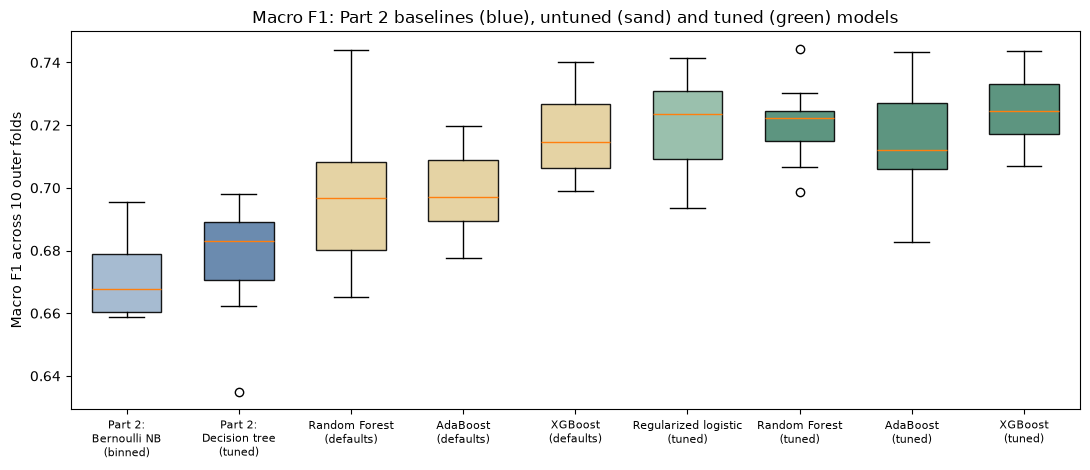

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.8))
names = list(results)
palette = ['#9db4cc', '#5b7fa6'] + ['#e3cf9a'] * 3 + ['#8fb9a4'] + ['#4b8a72'] * 3
bp = ax.boxplot([results[n]['test_f1_macro'] for n in names], vert=True, patch_artist=True, widths=.62,
                tick_labels=[n.replace(' (', '\n(').replace('Part 2: ', 'Part 2:\n') for n in names])
for patch, colour in zip(bp['boxes'], palette):
    patch.set(facecolor=colour, alpha=.9)
ax.set(ylabel='Macro F1 across 10 outer folds', title='Macro F1: Part 2 baselines (blue), untuned (sand) and tuned (green) models')
ax.tick_params(axis='x', labelsize=8)
plt.tight_layout()
plt.show()

In [7]:
# Paired comparisons on identical folds, with the Nadeau-Bengio correction for overlapping training sets
def corrected_paired_t(a, b, n_test_over_train=0.25):
    d = np.asarray(a) - np.asarray(b)
    k = len(d)
    t = d.mean() / np.sqrt((1 / k + n_test_over_train) * d.var(ddof=1))
    return d.mean(), t, 2 * stats.t.sf(abs(t), df=k - 1)

part3_tuned = ['Regularized logistic (tuned)', 'Random Forest (tuned)', 'AdaBoost (tuned)', 'XGBoost (tuned)']
best_name = max(part3_tuned, key=lambda n: results[n]['test_f1_macro'].mean())
print('Best Part 3 model by nested-CV macro F1:', best_name)

pairs = [(best_name, 'Part 2: Decision tree (tuned)'), (best_name, 'Part 2: Bernoulli NB (binned)')]
pairs += [('XGBoost (tuned)', 'XGBoost (defaults)'), ('Random Forest (tuned)', 'Random Forest (defaults)'),
          ('AdaBoost (tuned)', 'AdaBoost (defaults)')]
pairs += [(a, b) for a, b in [('XGBoost (tuned)', 'Random Forest (tuned)'), ('XGBoost (tuned)', 'AdaBoost (tuned)'),
                              ('XGBoost (tuned)', 'Regularized logistic (tuned)')] if a != best_name or b != best_name]
rows = []
for a, b in pairs:
    for metric in ['f1_macro', 'roc_auc_ovr']:
        diff, t, p = corrected_paired_t(results[a][f'test_{metric}'], results[b][f'test_{metric}'])
        rows.append({'A': a, 'B': b, 'metric': metric, 'mean(A-B)': round(diff, 4), 't': round(t, 2), 'p (corrected)': round(p, 4)})
display(pd.DataFrame(rows))

Best Part 3 model by nested-CV macro F1: XGBoost (tuned)


,A,B,metric,mean(A-B),t,p (corrected)
0,XGBoost (tuned),Part 2: Decision tree (tuned),f1_macro,0.0473,4.06,0.0028
1,XGBoost (tuned),Part 2: Decision tree (tuned),roc_auc_ovr,0.0491,8.90,0.0000
2,XGBoost (tuned),Part 2: Bernoulli NB (binned),f1_macro,0.0544,6.20,0.0002
3,XGBoost (tuned),Part 2: Bernoulli NB (binned),roc_auc_ovr,0.0377,10.21,0.0000
4,XGBoost (tuned),XGBoost (defaults),f1_macro,0.0089,1.68,0.1268
5,XGBoost (tuned),XGBoost (defaults),roc_auc_ovr,0.0077,2.52,0.0326
6,Random Forest (tuned),Random Forest (defaults),f1_macro,0.0236,1.97,0.0799
7,Random Forest (tuned),Random Forest (defaults),roc_auc_ovr,-0.0024,-0.98,0.3504
8,AdaBoost (tuned),AdaBoost (defaults),f1_macro,0.0168,1.95,0.0826
9,AdaBoost (tuned),AdaBoost (defaults),roc_auc_ovr,0.0467,11.14,0.0000


## 3. Regularization: Ridge, Lasso and Elastic-Net

Multinomial logistic regression with penalty strength `1/C` and mixing `l1_ratio` is the linear model for a three-class task: `l1_ratio = 0` is **Ridge** (shrinks all weights, keeps them all), `1` is **Lasso** (drives weights exactly to zero, i.e. feature selection), and `0.5` is **Elastic-Net** (a mixture that keeps groups of correlated features). The Part 1 matrix has 239 columns, many of them correlated one-hot indicators and correlated semester measurements, which is exactly where regularization matters.

Selected: {'C': np.float64(0.31622776601683794), 'l1_ratio': 1.0} | inner 5-fold macro F1 = 0.7204


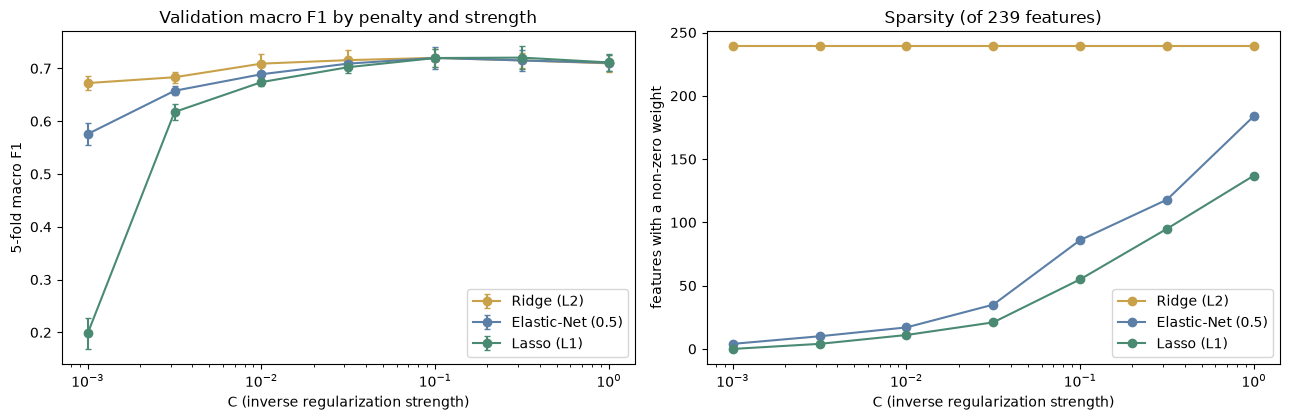

In [8]:
logit_search = grid(LOGIT_GRID, make_logit(), cv=5).fit(X_train, y_train)
print('Selected:', {k.replace('model__', ''): v for k, v in logit_search.best_params_.items()},
      f'| inner 5-fold macro F1 = {logit_search.best_score_:.4f}')
cvr = pd.DataFrame(logit_search.cv_results_)
cvr['penalty'] = cvr['param_model__l1_ratio'].map({0.0: 'Ridge (L2)', 0.5: 'Elastic-Net (0.5)', 1.0: 'Lasso (L1)'})
cvr['C'] = cvr['param_model__C'].astype(float)

# Sparsity: number of non-zero coefficients per fitted model on the full training partition
prep = continuous_preprocessing().fit(X_train)
Xt = prep.transform(X_train)
sparsity = {}
for ratio, label in [(0.0, 'Ridge (L2)'), (0.5, 'Elastic-Net (0.5)'), (1.0, 'Lasso (L1)')]:
    counts = []
    for C in LOGIT_GRID['model__C']:
        m = make_logit(C=C, l1_ratio=ratio).fit(Xt, y_train)
        counts.append(int((np.abs(m.coef_).max(axis=0) > 1e-8).sum()))   # features used by at least one class
    sparsity[label] = counts

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for label, colour in zip(['Ridge (L2)', 'Elastic-Net (0.5)', 'Lasso (L1)'], ['#c9a14a', '#5b7fa6', '#4b8a72']):
    sub = cvr[cvr.penalty == label].sort_values('C')
    axes[0].errorbar(sub.C, sub.mean_test_score, yerr=sub.std_test_score, marker='o', color=colour, label=label, capsize=2)
    axes[1].plot(LOGIT_GRID['model__C'], sparsity[label], marker='o', color=colour, label=label)
axes[0].set(xscale='log', xlabel='C (inverse regularization strength)', ylabel='5-fold macro F1', title='Validation macro F1 by penalty and strength')
axes[1].set(xscale='log', xlabel='C (inverse regularization strength)', ylabel='features with a non-zero weight', title=f'Sparsity (of {Xt.shape[1]} features)')
axes[0].legend(); axes[1].legend()
plt.tight_layout()
plt.show()

## 4. Hyperparameter search: how sensitive is each ensemble?

The final searches below run on the **full training partition** (5 inner folds, 40 sampled configurations) to pick the configurations that are refit for the test evaluation. The spread of validation scores across the sampled configurations shows how much tuning can matter for each model.

In [9]:
FINAL_SEARCH = {
    'Random Forest (tuned)': RandomizedSearchCV(with_model(continuous_preprocessing(), make_rf()), SPACES['rf'], n_iter=40,
                                                scoring='f1_macro', cv=inner_cv(5), n_jobs=4, random_state=SEED),
    'AdaBoost (tuned)': RandomizedSearchCV(with_model(continuous_preprocessing(), make_ada()), SPACES['ada'], n_iter=40,
                                           scoring='f1_macro', cv=inner_cv(5), n_jobs=4, random_state=SEED),
    'XGBoost (tuned)': RandomizedSearchCV(with_model(continuous_preprocessing(), make_xgb()), SPACES['xgb'], n_iter=40,
                                          scoring='f1_macro', cv=inner_cv(5), n_jobs=4, random_state=SEED),
}
for name, search in FINAL_SEARCH.items():
    start = time.time()
    search.fit(X_train, y_train)
    scores = search.cv_results_['mean_test_score']
    params = {k.replace('model__', ''): (round(v, 4) if isinstance(v, float) else v) for k, v in search.best_params_.items()}
    print(f'{name}: best inner macro F1 = {search.best_score_:.4f} | sampled range {scores.min():.3f}-{scores.max():.3f} | {time.time() - start:.0f}s')
    print('   ', params)

Random Forest (tuned): best inner macro F1 = 0.7281 | sampled range 0.624-0.728 | 206s
    {'class_weight': 'balanced', 'max_depth': 16, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 225}


AdaBoost (tuned): best inner macro F1 = 0.7177 | sampled range 0.656-0.718 | 620s
    {'estimator__max_depth': 4, 'learning_rate': np.float64(0.1842), 'n_estimators': 369}


XGBoost (tuned): best inner macro F1 = 0.7315 | sampled range 0.689-0.731 | 229s
    {'colsample_bytree': np.float64(0.449), 'learning_rate': np.float64(0.0203), 'max_depth': 5, 'min_child_weight': 4, 'n_estimators': 420, 'reg_alpha': np.float64(0.0018), 'reg_lambda': np.float64(2.1609), 'subsample': np.float64(0.6203)}


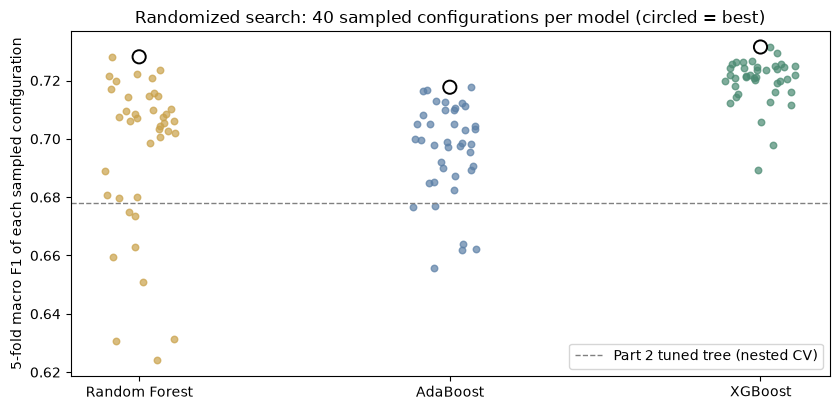

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
rng = np.random.default_rng(SEED)
for i, (name, search) in enumerate(FINAL_SEARCH.items()):
    scores = search.cv_results_['mean_test_score']
    ax.scatter(i + rng.uniform(-.12, .12, len(scores)), scores, s=22, alpha=.7, color=['#c9a14a', '#5b7fa6', '#4b8a72'][i])
    ax.scatter([i], [scores.max()], s=90, facecolor='none', edgecolor='black', lw=1.4)
ax.set_xticks(range(3), [n.replace(' (tuned)', '') for n in FINAL_SEARCH])
ax.axhline(results['Part 2: Decision tree (tuned)']['test_f1_macro'].mean(), color='grey', ls='--', lw=1, label='Part 2 tuned tree (nested CV)')
ax.set(ylabel='5-fold macro F1 of each sampled configuration', title='Randomized search: 40 sampled configurations per model (circled = best)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 5. Fit the final models on the full training partition

In [11]:
final = {
    'Part 2: Bernoulli NB (binned)': with_model(binned_preprocessing(), BernoulliNB(binarize=None)).fit(X_train, y_train),
    'Part 2: Decision tree (tuned)': grid(TREE_GRID, DecisionTreeClassifier(random_state=SEED), cv=5).fit(X_train, y_train).best_estimator_,
    'Regularized logistic (tuned)': logit_search.best_estimator_,
    'Random Forest (tuned)': FINAL_SEARCH['Random Forest (tuned)'].best_estimator_,
    'AdaBoost (tuned)': FINAL_SEARCH['AdaBoost (tuned)'].best_estimator_,
    'XGBoost (tuned)': FINAL_SEARCH['XGBoost (tuned)'].best_estimator_,
}
print('Fitted:', ', '.join(final))

Fitted: Part 2: Bernoulli NB (binned), Part 2: Decision tree (tuned), Regularized logistic (tuned), Random Forest (tuned), AdaBoost (tuned), XGBoost (tuned)


## 6. Held-out test evaluation (one look, after every choice is fixed)

The test set is scored once. Because it holds only 885 students (159 `Enrolled`), each macro F1 is reported with a **95 % bootstrap interval** (2,000 resamples of the test students), and the interval of the *paired difference* to the Part 2 tuned tree is reported for each model, so we can tell a real gain from noise.

In [12]:
preds, probas = {}, {}
rows = []
for name, model in final.items():
    preds[name] = model.predict(X_test)
    probas[name] = model.predict_proba(X_test)
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds[name]),
        'Balanced acc.': balanced_accuracy_score(y_test, preds[name]),
        'Macro F1': f1_score(y_test, preds[name], average='macro'),
        'ROC-AUC (OvR)': roc_auc_score(y_test, probas[name], multi_class='ovr', average='macro'),
        **{f'Recall {c}': class_recall(y_test, preds[name], i) for c, i in CLASS_ID.items()},
    })
test_table = pd.DataFrame(rows).set_index('Model')

rng = np.random.default_rng(SEED)
y_arr = y_test.to_numpy()
boot = rng.integers(0, len(y_arr), size=(2000, len(y_arr)))
f1_boot = {n: np.array([f1_score(y_arr[idx], p[idx], average='macro') for idx in boot]) for n, p in preds.items()}
ref = 'Part 2: Decision tree (tuned)'
ci = {n: np.percentile(v, [2.5, 97.5]) for n, v in f1_boot.items()}
test_table['Macro F1 95% CI'] = [f'[{ci[n][0]:.3f}, {ci[n][1]:.3f}]' for n in test_table.index]
test_table['F1 gain vs Part 2 tree [95% CI]'] = [
    '–' if n == ref else f'{(f1_boot[n] - f1_boot[ref]).mean():+.3f} [{np.percentile(f1_boot[n] - f1_boot[ref], 2.5):+.3f}, {np.percentile(f1_boot[n] - f1_boot[ref], 97.5):+.3f}]'
    for n in test_table.index]
display(test_table.round(3))

,Accuracy,Balanced acc.,Macro F1,ROC-AUC (OvR),Recall Dropout,Recall Enrolled,Recall Graduate,Macro F1 95% CI,F1 gain vs Part 2 tree [95% CI]
Model,,,,,,,,,
Part 2: Bernoulli NB (binned),0.719,0.688,0.678,0.860,0.658,0.610,0.796,"[0.646, 0.709]","+0.005 [-0.027, +0.037]"
Part 2: Decision tree (tuned),0.707,0.688,0.674,0.848,0.648,0.648,0.767,"[0.642, 0.704]",–
Regularized logistic (tuned),0.740,0.713,0.701,0.886,0.701,0.635,0.803,"[0.668, 0.731]","+0.028 [-0.004, +0.057]"
Random Forest (tuned),0.765,0.725,0.721,0.889,0.718,0.604,0.853,"[0.689, 0.751]","+0.047 [+0.019, +0.074]"
AdaBoost (tuned),0.722,0.697,0.685,0.866,0.687,0.623,0.781,"[0.653, 0.714]","+0.011 [-0.018, +0.039]"
XGBoost (tuned),0.731,0.707,0.694,0.892,0.697,0.635,0.787,"[0.661, 0.724]","+0.020 [-0.006, +0.046]"


Best model chosen from nested-CV scores: XGBoost (tuned)
              precision    recall  f1-score   support

     Dropout      0.825     0.697     0.756       284
    Enrolled      0.419     0.635     0.505       159
    Graduate      0.861     0.787     0.823       442

    accuracy                          0.731       885
   macro avg      0.702     0.707     0.694       885
weighted avg      0.770     0.731     0.744       885



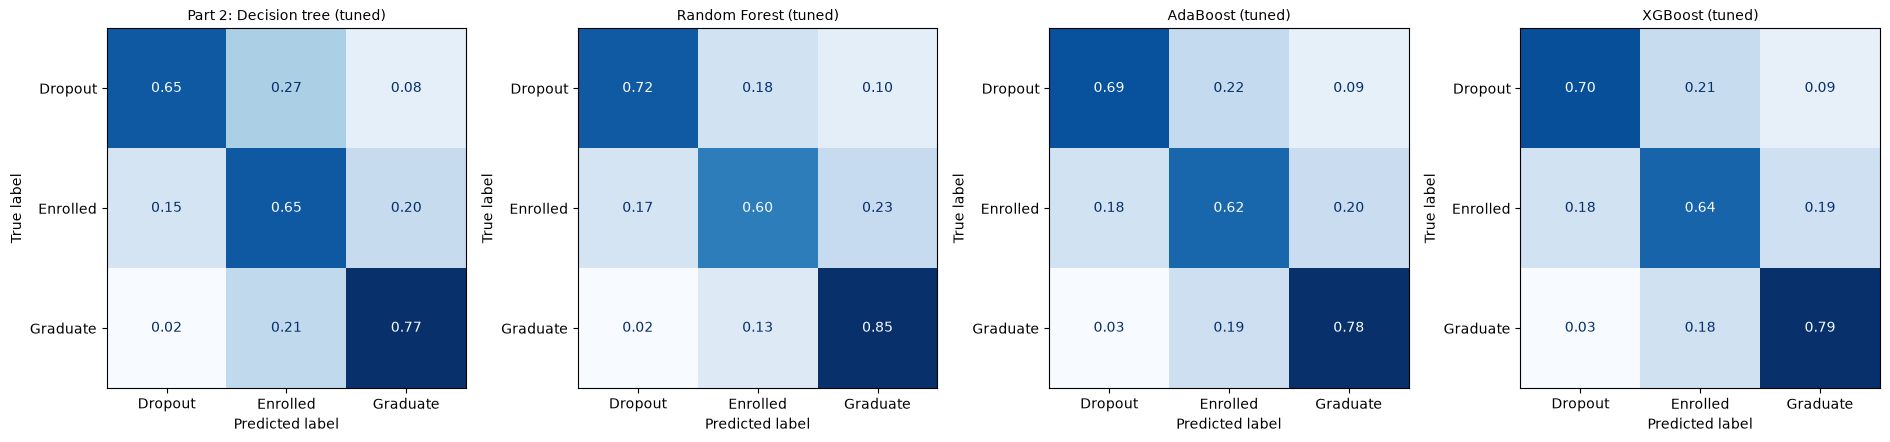

In [13]:
best_model = best_name
print('Best model chosen from nested-CV scores:', best_model)
print(classification_report(y_test, preds[best_model], target_names=CLASSES, digits=3))

show = [ref, 'Random Forest (tuned)', 'AdaBoost (tuned)', 'XGBoost (tuned)']
fig, axes = plt.subplots(1, 4, figsize=(19, 4.6))
for ax, name in zip(axes, show):
    ConfusionMatrixDisplay.from_predictions(y_test, preds[name], display_labels=CLASSES, normalize='true',
                                            cmap='Blues', values_format='.2f', ax=ax, colorbar=False)
    ax.set_title(name, fontsize=10)
plt.tight_layout()
plt.show()

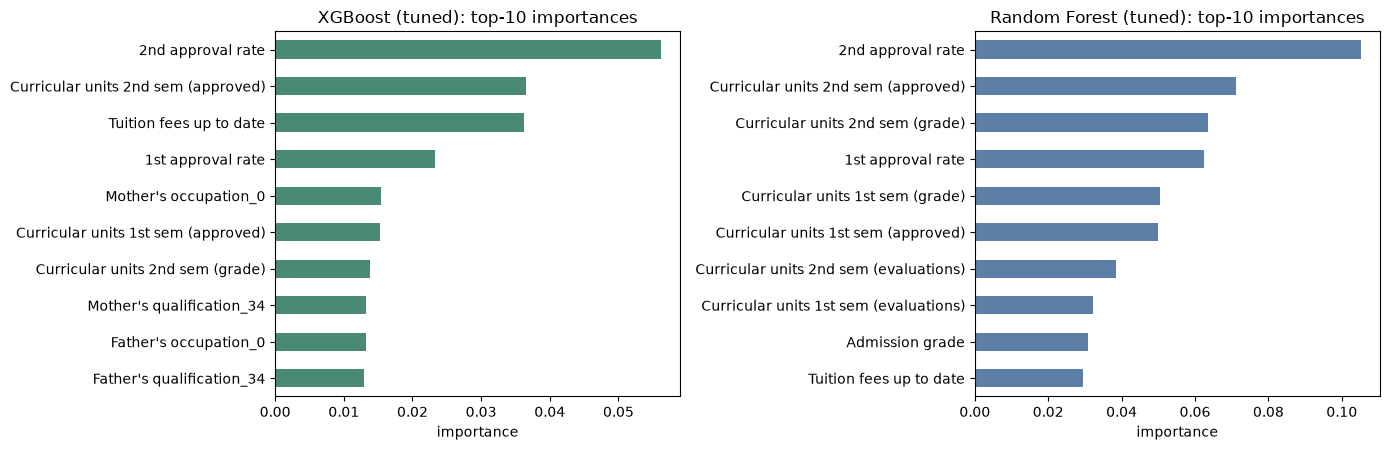

In [14]:
# Which features drive the tuned XGBoost and Random Forest models?
names_out = [n.split('__', 1)[1] for n in final['XGBoost (tuned)'].named_steps['prep'].named_steps['preprocess'].get_feature_names_out()]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, name, colour in zip(axes, ['XGBoost (tuned)', 'Random Forest (tuned)'], ['#4b8a72', '#5b7fa6']):
    imp = pd.Series(final[name].named_steps['model'].feature_importances_, index=names_out).sort_values(ascending=False)
    imp.head(10)[::-1].plot.barh(ax=ax, color=colour)
    ax.set(title=f'{name}: top-10 importances', xlabel='importance')
plt.tight_layout()
plt.show()

## 7. Comparison and discussion

**Headline result.** Ensembles and a regularized linear model improve clearly on the Part 2 baselines, but they are close to one another. In nested cross-validation (10 outer folds, tuning done inside each training fold) the tuned models score macro F1 **0.725 (XGBoost)**, 0.721 (Random Forest), 0.720 (regularized logistic regression) and 0.715 (AdaBoost), against 0.678 for the Part 2 tuned tree and 0.671 for Bernoulli Naive Bayes measured on the same folds. The XGBoost gain over the Part 2 tree is +0.047 macro F1 (corrected paired p = 0.003) and +0.049 ROC-AUC (0.896 vs 0.847, p < 0.001). Among the Part 3 models, macro F1 differences are **not** significant (XGBoost vs Random Forest p = 0.22, vs AdaBoost p = 0.20, vs logistic regression p = 0.40); XGBoost's one clear edge is ranking quality, with ROC-AUC significantly above Random Forest (0.896 vs 0.890, p = 0.012), AdaBoost (0.884, p = 0.004) and logistic regression (0.890, p = 0.025). By the rule fixed beforehand, XGBoost was chosen as the best model from the nested-CV scores alone.

**Ensembles and tuning.** Boosting and bagging reduce the variance that limited the single tree: even untuned, XGBoost (0.716), AdaBoost (0.698) and Random Forest (0.697) beat the tuned tree. Tuning added a further +0.009 (XGBoost, p = 0.13), +0.017 (AdaBoost, p = 0.08) and +0.024 (Random Forest, p = 0.08) macro F1; none of these gains is individually significant, although tuning clearly mattered for AdaBoost's ROC-AUC (0.837 to 0.884, p < 0.001). The 40-draw randomized searches show different sensitivity: XGBoost's sampled configurations span only 0.689-0.731 inner macro F1, so it is forgiving to tune; Random Forest spans 0.624-0.728 and AdaBoost 0.656-0.718, so poor draws cost much more. Each search's best inner score (0.728, 0.718, 0.732) sits slightly above its nested score (0.721, 0.715, 0.725), the expected optimism of selecting the maximum, and the reason nested CV is used for the comparison. Tuning also changed *how* the models err: default Random Forest had cross-validated `Enrolled` recall of only 0.346 (accuracy 0.780), whereas tuned Random Forest reaches 0.610 and tuned XGBoost 0.615, at the price of some accuracy. We did not isolate which hyperparameter produces this shift.

**Regularization.** Multinomial logistic regression with a tuned penalty is as good as the tree ensembles (nested macro F1 0.720; XGBoost's 0.725 is not significantly different, p = 0.40). The grid selected a Lasso penalty (`l1_ratio` = 1, `C` ≈ 0.32), which keeps roughly 95 of the 239 columns (read from the sparsity plot). For `C` ≥ 0.1 all three penalties (Ridge, Elastic-Net, Lasso) reach about 0.72 macro F1, so the data do not strongly prefer one; they differ at strong regularization (`C` = 0.001), where Lasso zeroes almost every weight and falls to 0.20 while Ridge degrades gracefully to 0.67. Lasso therefore offers a comparable model that uses well under half of the features. That a linear model matches the ensembles suggests that most of the usable signal is close to linear in the engineered features, so the ceiling near 0.72-0.73 is more likely a limit of the information in the data than of the model class.

**Held-out test set (scored once).** The tuned models scored macro F1 0.721 (Random Forest), 0.701 (logistic regression), 0.694 (XGBoost), 0.685 (AdaBoost), against 0.678 and 0.674 for the Part 2 models; XGBoost has the best test ROC-AUC (0.892). The test ranking differs from the cross-validation ranking: Random Forest leads on test, XGBoost in CV. We report this as it is. The test set has only 885 students (159 `Enrolled`), and the bootstrap 95 % intervals for macro F1 are about ±0.03 wide and overlap across all models (for example XGBoost [0.661, 0.724], Random Forest [0.689, 0.751]). Only Random Forest's gain over the Part 2 tree has an interval excluding zero (+0.047 [+0.019, +0.074]); XGBoost's is +0.020 [-0.006, +0.046]. The pooled nested-CV estimate uses four times more students and is the more reliable guide, so we do not re-select the model after seeing test scores, and we do not claim XGBoost and Random Forest differ.

**Where the models still fail.** `Enrolled` remains the hardest class: for XGBoost the test recall is 0.635 but precision only 0.42 (F1 0.505), against 0.756 and 0.823 for `Dropout` and `Graduate`. Both leading models rank features similarly (2nd-semester approval rate, a Part 1 construction, is first in both, followed by approved units and tuition status or grades), but XGBoost also gives weight to several one-hot parental occupation and qualification columns, which are socioeconomic proxies; this is a point for the Part 4 interpretability and fairness discussion.

*Caveats.* Outer folds overlap, so the corrected paired test, not the raw standard deviation, is the basis for "tied"; we ran many comparisons and did not adjust for multiple testing, so borderline p-values (0.01-0.1) should be read cautiously. Costs differ: the nested AdaBoost run took about 25 minutes against 8 for XGBoost and Random Forest on four cores.
